<a href="https://colab.research.google.com/github/hbprosper/dihiggs/blob/main/code/heft_train_curriculum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Higgs Effective Field Theory (HEFT) Study: Training with a Curriculum
> Created: Feb 12, 2024 Pushpa Bhat (Fermilab), Nicola de Filippis (Bari),<br> Kurtis Johnson,  Harrison B. Prosper, Ryne Starnes (FSU)<br>
> Updated: Mar 22, 2026 HBP: Modernize.<br>
> Updated: Aug 21, 2026 HBP: Move test code into separate notebook.<br>
> Updated: Oct 29, 2026 HBP: Curriculum learning version of heft_train.ipynb.<br>

## Introduction

**This notebook is `heft_train.ipynb` with one change: the training data are presented as a curriculum, starting with the smallest cross sections.** Everything else (the model, the losses, the positivity constraint, the learning-rate schedule and the monitoring) is the same, so that runs of the two notebooks can be compared directly with `heft_test.ipynb`. The curriculum is explained in the section *Curriculum learning* below.


In this notebook, we model the HEFT di-Higgs cross section, $d\sigma / dm_{hh}$, [1], using simulated spectra binned into 15 GeV bins in the di-Higgs mass, $m_{hh}$). The spectra are mapped to dimensionless bins of width $10^{-2}$. The HEFT parameter space is defined by the 5 parameters $\theta = c_{hhh}, c_{t}, c_{tt}, c_{ggh}, c_{gghh}$ and the cross section is given by
\begin{align}
    \sigma(m_{gg}, \theta) & = \boldsymbol{c}(\theta) \cdot \boldsymbol{a}(m_{hh}), 
\end{align}
where the vector of polynomials $\boldsymbol{c}(\theta)$ is [1]

\begin{align*}
    \boldsymbol{c}(\theta) & = (\\
             c_{t}^4,\\
             c_{tt}^2,\\
             c_{t}^2 c_{hhh}^2,\\
             c_{ggh}^2 c_{hhh}^2,\\
             c_{gghh}^2,\\
             c_{tt} c_{t}^2,\\             
             c_{hhh} c_{t}^3,\\
             c_{t} c_{hhh} c_{tt},\\
             c_{ggh} c_{hhh} c_{tt},\\
             c_{tt} c_{gghh},\\
             c_{ggh} c_{hhh} c_{t}^2,\\
             c_{gghh} c_{t}^2, \\
             c_{hhh}^2 c_{ggh} c_{t},\\
             c_{gghh} c_{t} c_{hhh},\\
             c_{ggh} c_{gghh} c_{hhh},\\
             c_{t}^3 c_{ggh},\\
             c_{t} c_{tt} c_{ggh},\\
             c_{t} c_{ggh}^2 c_{hhh},\\
             c_{t} c_{ggh} c_{gghh}, 
             c_{t}^2 c_{ggh}^2,\\
             c_{tt} c_{ggh}^2,\\
             c_{ggh}^3 c_{hhh},\\
             c_{ggh}^2 c_{gghh}\\
             )
\end{align*}
The observable-dependent sequence of coefficients, $\boldsymbol{a}(m_{hh})$, is the object to be modeled. 

## Model

The 23 functions $a_i(m_{hh})$ are modeled using a *single* deep neural network with one input, $m_{hh}$, and 23 outputs, one for each function and a 1-parameter neural network. The training data for this notebook are prepared in the notebook `heft_prepare_data.ipynb`, which also prepares the test data.

## Bibliography
  1. Lina Alasfar *et al.*, arXiv:2304.01968v1

## Installation

 1. Clone the `dihiggs` repo.
 2. Use pip install to install the `dihiggs` Python  module, which is the folder within the repo of the same name.
```bash
    git clone https://github.com/hbprosper/dihiggs
    cd dihiggs
    pip install -e .
```

Instead of working directly in folder `dihiggs/code` it is better to create another folder, e.g., `work`, and work in there. 

```bash
    mkdir work
    cd work
    cp -r <path-to-cloned-dihiggs-repo>/code .
    ln -s <path-to-cloned-dihiggs-repo>/data .
```

That way, if your local installation of `dihiggs` needs to be updated using
```bash
    cd <path-to-cloned-dihiggs-repo>
    git pull
```
this won't cause conflicts with your codes in `work`.

In [1]:
# ------------------------------------------------------------------
# Google Colab setup (nothing happens when run outside Colab)
#   1. clone the dihiggs repository, which holds the data files,
#   2. install the dihiggs package, which also installs drwho,
#   3. make dihiggs/code the working directory so that the relative
#      paths used below (../data, runs/, figures/) work as they do locally.
#
# Training is much faster on a GPU: in Colab choose
#   Runtime > Change runtime type > GPU.
# ------------------------------------------------------------------
import os, sys, subprocess, importlib

IN_COLAB = 'google.colab' in sys.modules

# Each Colab notebook runs on its own temporary machine, so a model trained
# in heft_train.ipynb is invisible to heft_test.ipynb unless it is saved
# somewhere both can reach. With USE_DRIVE = True the runs/ folder lives in
# your Google Drive (MyDrive/dihiggs/runs), which also keeps the trained
# model safe if the Colab runtime disconnects. You will be asked to allow
# access to your Drive.
USE_DRIVE = True

if IN_COLAB:
    REPO = '/content/dihiggs'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q',
                        'https://github.com/hbprosper/dihiggs.git', REPO],
                       check=True)
    # A regular (non-editable) install can be imported at once; after an
    # editable install (pip install -e) the runtime must be restarted
    # before "import dihiggs" works.
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', REPO],
                   check=True)
    importlib.invalidate_caches()
    os.chdir(f'{REPO}/code')

    if USE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_runs = '/content/drive/MyDrive/dihiggs/runs'
        os.makedirs(drive_runs, exist_ok=True)
        if not os.path.exists('runs'):
            os.symlink(drive_runs, 'runs')
        print(f'runs/ is stored in {drive_runs}')

print(f'working directory: {os.getcwd()}')

working directory: /Users/harry/Projects/Tutorials/GitHub/dihiggs/code


In [2]:
import os, sys

# the standard module for tabular data
import pandas as pd

# the standard module for array manipulation
import numpy as np

# the standard modules for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

# pytorch
import torch
import torch.nn as nn
import torch.utils.data as td

# module for shell utilities
import shutil

# ML and other utilities 
import drwho.nn as mlp
import drwho.data as dat
import drwho.monitor as mon

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  "font.size": 12
})

## Computational device

In [3]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\n\tAvailable device: {str(DEVICE):4s}\n')


	Available device: cpu 



## Load training data

In [4]:
datafile = f'../data/heft_wide_gauss_traindata_13TeV.csv.gz'

print(f'loading {datafile}')
df = pd.read_csv(datafile)

sample_size = len(df)

# Fingerprint of the training file, saved in the configuration below so that
# heft_checks.ipynb can confirm which data a saved model was trained on.
import hashlib
with open(datafile, 'rb') as f:
    traindata_sha256 = hashlib.sha256(f.read()).hexdigest()
print(f'sample size: {sample_size}')

print(f'''
    min(sigma):  {df.sigma.min():10.3e} pb
    max(sigma):  {df.sigma.max():10.3e} pb
    avg(sigma):  {df.sigma.mean():10.3e} pb
    ''')
# Before Oct 27 2026: 356_958
# After  Oct 28 2026: 318_202

loading ../data/heft_wide_gauss_traindata_13TeV.csv.gz
sample size: 317306

    min(sigma):   6.394e-07 pb
    max(sigma):   3.168e+01 pb
    avg(sigma):   1.091e-01 pb
    


## Estimated noise in each bin

The $\chi^2$ loss below needs the statistical noise $\sigma_k$ of each POWHEG bin, which POWHEG does not provide. As explained in `heft_test.ipynb`, the bin-to-bin jitter of the spectra behaves like counting noise from a fixed number of events per spectrum, $N_\text{eff}$, so that

$$
\sigma_k^2 = \frac{f_k \, \sigma_\text{tot}}{N_\text{eff}} ,
$$

where $f_k$ is the cross section in bin $k$ and $\sigma_\text{tot}$ the total cross section of the spectrum. Here $N_\text{eff}$ is estimated from the **training spectra only**, so that no information from the holdout spectra enters the training.

**One event's worth of variance.** The formula gives an absurdly small $\sigma_k$ to a bin expected to hold less than one simulated event, $N_\text{eff} f_k/\sigma_\text{tot} \lesssim 1$, and there are many such bins near threshold and in small spectra. As a training weight, $1/\sigma_k^2$, such bins would dominate everything else, and in tests they made the training unstable. So each bin is given the variance of one additional event, which a bin of that spectrum cannot be known better than:

$$
\sigma_k^2 = \left( f_k + \frac{\sigma_\text{tot}}{N_\text{eff}} \right) \frac{\sigma_\text{tot}}{N_\text{eff}} .
$$

For bins holding many events the extra term is negligible. Each row of the training data then gets its noise variance $\sigma_k^2$.

In [5]:
# total cross section of the spectrum to which each row belongs
df['sigma_tot'] = df.groupby('ID')['sigma'].transform('sum')

# The training spectra as an array [number of spectra, 80]. Rows with zero
# cross section were dropped from the training file; they come back as 0.
spectra = df.pivot_table(index='ID', columns='mhh', values='sigma', fill_value=0.0)
F     = spectra.to_numpy(np.float64)
F_tot = F.sum(axis=1, keepdims=True)

# bin-to-bin jitter: each bin minus the average of its two neighbours
f_mid, f_lo, f_hi = F[:, 1:-1], F[:, :-2], F[:, 2:]
D = f_mid - (f_lo + f_hi) / 2
good = (f_mid > 0) & (f_lo > 0) & (f_hi > 0)

# With independent noise, q = D^2 / (sigma_tot (f_k + (f_{k-1} + f_{k+1})/4)) is
# 1/N_eff times the square of a standard Gaussian, whose median is 0.4549.
q = np.full_like(D, np.nan)
q[good] = D[good]**2 / (F_tot * (f_mid + (f_lo + f_hi) / 4))[good]

# use only bins from 570 GeV (x = 0.215) upward, where the spectra are smooth
smooth = spectra.columns.to_numpy()[1:-1] >= (38 - 17 + 0.5) / 100
N_EFF  = 0.4549 / np.nanmedian(q[:, smooth])

# noise variance of each training row, including the variance of one extra
# event, sigma_tot / N_eff, so that no bin claims to be known better than that
one_event = df.sigma_tot / N_EFF
df['noise_var'] = (df.sigma + one_event) * one_event

print(f'training spectra: {len(spectra)}')
print(f'effective number of events per spectrum: N_eff = {N_EFF:.0f}')

training spectra: 3989
effective number of events per spectrum: N_eff = 38024


## Load model

The model is described in the file `heftnet.py`.

In [6]:
from dihiggs import heftnet as NN

print(f'''
    Model name: {NN.NAME}
    Features:   {NN.FEATURES}
    Target:     {NN.TARGET}
''')


    Model name: heftnet
    Features:   ['mhh', 'klambda', 'CT', 'CTT', 'CGGH', 'CGGHH']
    Target:     sigma



## Configuration

`mlp.Config` is a simple Python class to record the configuration of the network and training.

**Note**: the `test_size` here is the size of the data from the traindata file that will be used as a first test of the quality of the modeling. The more complete test is in `heft_test.ipynb`.

In [7]:
batch_size = 2048
train_size = int(0.850*sample_size)
test_size  = int(0.130*sample_size)
val_size   = sample_size - train_size - test_size

train_size, val_size, test_size

(269710, 6347, 41249)

## Choice of loss and positivity constraint

### The three losses

Let $t$ be the POWHEG cross section in a bin and $f$ the model's prediction. The average over a batch of one of three losses is minimised:

| `LOSS` | loss per row | what the minimum estimates |
| :--- | :--- | :--- |
| `'L1'` | $\lvert f - t \rvert / S$ | the median of $t$ given the inputs |
| `'MSE'` | $(f - t)^2 / S^2$ | the mean of $t$ given the inputs |
| `'CHI2'` | $(f - t)^2 / \sigma_k^2$ | the mean, with each bin weighted by its precision |

**L1 and MSE** treat an error of $10^{-4}$ pb the same way in every bin. Since the cross sections range from about $10^{-6}$ to $30$ pb per bin, the training is dominated by the largest cross sections, and small spectra, together with the region near threshold where the cross section is small, get little attention.

**CHI2** measures every error in units of the POWHEG noise in that bin, $\sigma_k$ (estimated above). A bin where POWHEG is precise counts for more, and a bin where it is noisy counts for less. That is the weighting a statistician would choose, and the loss is the $\chi^2$ per bin: about 1 for a model that agrees with POWHEG within the noise, as measured in `heft_test.ipynb`.

**Status of CHI2: experimental.** In tests of 20,000 iterations it trained much worse than L1: a median holdout $\chi^2/N$ of 382, against 3.8 for L1 after the same number of iterations, and RMS$/\sigma$ about 15 times larger. A ten times smaller learning rate did not help. A likely reason is that the weights $1/\sigma_k^2$ span about ten orders of magnitude, because $\sigma_k^2$ grows with $\sigma_\text{tot}^2$ and the total cross sections range from $10^{-3}$ to 400 pb. The loss then asks for the same relative precision in spectra whose sizes differ by five orders of magnitude. It did, however, give fewer negative predictions. Treat it as a starting point for experiments, not as a replacement for L1.

*A caveat for CHI2.* $\sigma_k$ is computed from the observed $t$, not from the unknown true cross section. A bin that fluctuates down gets a smaller $\sigma_k$ and so a larger weight, which pulls the fit slightly low. The relative size of this bias is about $1/n_k$, where $n_k = N_\text{eff}\, t/\sigma_\text{tot}$ is the number of events in the bin. That is well below the noise itself, except in bins with very few events.

**The scale $S$.** $S$ is the median cross section of the training rows. Dividing by it makes all three losses dimensionless. This changes nothing about the minimum, but it allows the positivity penalty below to have the same meaning for every loss. Note that the values of *different* losses still cannot be compared with each other. To compare runs with different losses, use RMS$/\sigma$ and $\chi^2/N$ in `heft_test.ipynb`.

### The positivity constraint

A cross section cannot be negative: it is an integral of $|\mathcal{M}|^2$, so it is $\ge 0$ for every $\theta$ and every $m_{hh}$. Nothing in the model enforces this, and the trained model does predict small negative values, mostly just above threshold.

With `POSITIVITY = True`, a penalty is added to the loss during training:

$$
R = R_\text{data} + \lambda \, \frac{1}{M} \sum_{j=1}^{M} \left( \frac{\max(0, -f_j)}{S} \right)^2 .
$$

* **Which points.** The $f_j$ are predictions at $M = 2048$ *random* points, drawn afresh at each iteration: $\theta$ from a Gaussian with the mean and standard deviation of the training points, and $x$ uniform over the training range of masses. Positivity must hold everywhere, not only at the 3,999 training points. The negative predictions we found were at holdout points, which the model had never seen.
* **What it does.** Only negative predictions are penalised, quadratically. Positive predictions cost nothing, so the penalty does not pull the model away from the data where the data are positive.
* **Why a penalty and not a hard constraint.** One could force positivity by passing the output through a positive function, for example $\log(1 + e^f)$. But that would destroy the exact polynomial dependence on the Wilson coefficients, $\sigma = \sum_i c_i(\theta)\, a_i(m_{hh})$, which is the central idea of the model. The penalty keeps the structure exact.
* **The strength $\lambda$.** It sets how much a negative excursion costs compared with an error in fitting the data: with $\lambda = 1$, a negative prediction of size $S$ costs as much as an L1 error of size $S$. Choose $\lambda$ by looking at the fraction of negative predictions printed at the end of this notebook, and at $\chi^2/N$ in `heft_test.ipynb`. Too large a $\lambda$ trades accuracy for positivity.
* **Monitoring.** The penalty is applied only in training mode. The training and validation losses written to the loss file are the data term alone, so runs with and without the constraint can be compared directly.

### Where each run is saved

Each choice is saved in its own folder, `runs/<DIRNAME>`: `L1Loss`, `MSELoss` or `Chi2Loss`, followed by `_positive` if the constraint is on. To test, check or export a run, set `DIRNAME` in `heft_test.ipynb`, `heft_checks.ipynb` (`CONFIG_FILE`) or `heft_export.ipynb` to the same name.

In [8]:
# ------------------------------------------------------------------
# Switches
# ------------------------------------------------------------------
LOSS       = 'L1'       # loss function: uses torch.nn.L1Loss (mean absolute error)
POSITIVITY = False      # add the positivity penalty?
LAMBDA     = 1.0        # strength of the positivity penalty (used if POSITIVITY)

# Curriculum learning settings
#
# DIFFICULTY controls which quantity defines "easy".
#   'bin_sigma'      — sort by the cross section of the individual bin (sigma_k).
#                      Rows with the largest sigma_k come first; they have the
#                      best signal-to-noise ratio and give the most reliable gradient.
#   'spectrum_sigma' — sort by the total cross section of the parent spectrum
#                      (sigma_tot = sum_k sigma_k). All bins from the same spectrum
#                      move together, so easy spectra are fully presented before
#                      hard ones are introduced.
#   'spectrum_snr'   — sort by sigma_tot / sqrt(w_j), the SNR of the spectrum.
#                      Not yet implemented; requires w_j in the training file.
DIFFICULTY = 'bin_sigma'   # default: 'bin_sigma'

# PACING controls the shape of the fraction ramp from START_FRACTION to 1.
#   'linear' — equal-sized steps: f(i) = f0 + (1-f0) * i / i_ramp
#   'log'    — slow start then faster: f(i) = f0^(1 - i/i_ramp)
#              Spends more time on easy examples before opening up to hard ones.
PACING = 'log'             # default: 'log'

START_FRACTION = 0.10   # fraction of training rows used at the start of training
RAMP_FRACTION  = 0.50   # fraction of the iterations after which all rows are used

# Random seed for reproducibility. Applied just before model creation.
SEED = 42

assert DIFFICULTY in ('bin_sigma', 'spectrum_sigma', 'spectrum_snr'), \
    f'unknown difficulty {DIFFICULTY!r}'
assert PACING in ('linear', 'log'), f'unknown pacing {PACING!r}'

# Short run-folder name. Full key is in runs/README.md.
#   L1  = nn.L1Loss;  curr = curriculum on
#   b   = bin_sigma,  s = spectrum_sigma
#   lin = linear pacing, log = log pacing
_diff_code   = {'bin_sigma': 'b', 'spectrum_sigma': 's', 'spectrum_snr': 'snr'}[DIFFICULTY]
_pacing_code = {'linear': 'lin', 'log': 'log'}[PACING]
DIRNAME = {'L1': 'L1', 'MSE': 'MSE', 'CHI2': 'Chi2'}[LOSS]
if POSITIVITY:
    DIRNAME += '_pos'
DIRNAME += f'_curr_{_diff_code}_{_pacing_code}'

# S: the median cross section of the training rows (pb)
SCALE = float(np.median(df.sigma.to_numpy()[:train_size]))

print(f'loss: {LOSS}    positivity: {POSITIVITY}' + (f' (lambda = {LAMBDA})' if POSITIVITY else ''))
print(f'scale S = {SCALE:.3e} pb')
print(f'curriculum: DIFFICULTY={DIFFICULTY}, PACING={PACING}')
print(f'  start fraction: {START_FRACTION:.0%}, all rows after {RAMP_FRACTION:.0%} of iterations')
print(f'seed: {SEED}')
print(f'run folder: runs/{DIRNAME}')


loss: L1    positivity: False
scale S = 1.183e-02 pb
curriculum: DIFFICULTY=bin_sigma, PACING=log
  start fraction: 10%, all rows after 50% of iterations
seed: 42
run folder: runs/L1_curr_b_log


In [9]:
# DIRNAME is set by the switches above
NAME    = 'dihiggs' # Model name
BASE    = f'runs/{DIRNAME}'

# Choose whether to create or load a configuration file
load_existing_config = False

if load_existing_config:
    config = mlp.Config(f'{BASE}/{NAME}_config.yaml')
else:
    # Create new configuration
    config = mlp.Config(NAME, dirname=DIRNAME)

    # -------------------------------------------------------------
    # Model architecture (FCNN)
    # -------------------------------------------------------------
    config('model_name', NN.NAME)
    config('features', NN.FEATURES)
    config('target', NN.TARGET)
    config('activation', NN.ACTIVATION)
    config('traindata_sha256', traindata_sha256)  # which data were used

    # loss and positivity constraint
    config('loss', LOSS)
    config('positivity', POSITIVITY)
    config('lambda', LAMBDA if POSITIVITY else 0.0)
    config('loss_scale', SCALE)
    config('N_eff', float(N_EFF))

    # curriculum
    config('difficulty', DIFFICULTY)
    config('pacing', PACING)
    config('seed', SEED)
    config('start_fraction', START_FRACTION)
    config('ramp_fraction', RAMP_FRACTION)
    
    # -------------------------------------------------------------
    # Training configuration
    # -------------------------------------------------------------
    config('batch_size', batch_size) 
    config('train_size', train_size) # training sample size
    config('test_size',  test_size)  # test sample size
    config('val_size',   val_size)   # validation sample size
 
    config('monitor_step', 100)   # monitor training every n (=10) iterations
    config('frac', 0.015)         # save model if average loss decreases by more
                                  # than frac percent
    # -------------------------------------------------------------
    # Optimizer / scheduler configuration
    # -------------------------------------------------------------
    # A step comprises a given number of iterations, i.e.,
    # the number of steps with a fixed learning rate
    n_steps = 4

    # number of iterations
    n_iterations = 200_000

    # number of iterations per step
    config('n_steps', n_steps)    # number of training steps

    config('n_iterations', n_iterations)

    n_iters_per_step = int(n_iterations / n_steps)
    config('n_iters_per_step', n_iters_per_step)

    config('base_lr', 2.e-3)      # initial learning rate
    config('gamma', 0.5)          # learning rate scale factor
    
    print(f"\nSaving configuration to file {config('file/config')}\n")
    config.save()

print(config)


Saving configuration to file runs/L1_curr_b_log/dihiggs_config.yaml

name: dihiggs
file:
  losses: runs/L1_curr_b_log/dihiggs_losses.csv
  params: runs/L1_curr_b_log/dihiggs_params.pth
  init_params: runs/L1_curr_b_log/dihiggs_init_params.pth
  plots: runs/L1_curr_b_log/dihiggs_plots.png
  config: runs/L1_curr_b_log/dihiggs_config.yaml
model_name: heftnet
features:
- mhh
- klambda
- CT
- CTT
- CGGH
- CGGHH
target: sigma
activation: nn.ReLU
traindata_sha256: af0b220986b01474216e6cecaa236cb5b2aabe5a6c5e818520314b28e59e7d68
loss: L1
positivity: false
lambda: 0.0
loss_scale: 0.011832306161522851
N_eff: 38023.64035688936
difficulty: bin_sigma
pacing: log
seed: 42
start_fraction: 0.1
ramp_fraction: 0.5
batch_size: 2048
train_size: 269710
test_size: 41249
val_size: 6347
monitor_step: 100
frac: 0.015
n_steps: 4
n_iterations: 200000
n_iters_per_step: 50000
base_lr: 0.002
gamma: 0.5



### Train, validation, and test sets
There is some confusion in terminology regarding validation and test samples (or sets). We shall adhere to the defintions given here https://machinelearningmastery.com/difference-test-validation-datasets/):
   
  * __Training Dataset__: The sample of data used to fit the model.
  * __Validation Dataset__: The sample of data used to decide 1) whether the fit is reasonable (e.g., the model has not been overfitted), 2) decide which of several models is the best and 3) tune model hyperparameters.
  * __Test Dataset__: The sample of data used to provide an unbiased evaluation of a final model fit on the training dataset.

The validation set will be some small fraction of the training set and can be used, for example, to decide when to stop the training.

## Prepare Datasets and DataLoaders

### Datasets

The required datasets are extracted from the data that have been loaded into memory from the traindata file. Three disjoint datasets are created: `train_data`, `val_data`, and `test_data`. Another, called `train_data_val`, is a random subset of `train_data`. Most of the data read from the traindata file are used for training. The rest are used for monitoring the training and running a quick sanity check after training. A more thorough test is applied in `heft_test.ipynb`. 

The steps are:
 1. Get input features: `X`.
 2. Get targets: 'Y'.
 3. Create a training dataset: `train_data` of size `train_size`.
 4. Create a random subset of `train_data` called `train_data_val` of size `val_size`.
 5. Create a validation dataset: `val_data` of size `val_size`. The datasets `train_data_val` and `val_data` are used to monitor the training.
 6. Create test dataset: `test_data` of size `test_size`, which will be used for a first test of the quality of the training.

In [10]:
X = df[NN.FEATURES].to_numpy(dtype=np.float32)

# Target: the POWHEG cross section per bin (pb), one column.
# noise_var is no longer a training target. For scaled Poisson data,
# Var(sigma_k) = w_j * sigma_k is determined analytically from the
# cross section itself — there is nothing to learn.
Y = df[[NN.TARGET]].to_numpy(dtype=np.float32)

# ------------------------------------------------------------------
# Curriculum: sort the TRAINING rows (the first train_size rows) so
# that the easiest examples come first. Easy = large cross section =
# high signal-to-noise ratio = most reliable gradient information.
# The validation and test rows (which follow) are left unsorted.
# ------------------------------------------------------------------
if DIFFICULTY == 'bin_sigma':
    # Difficulty score = cross section of this individual bin.
    score = df.sigma.to_numpy()[:train_size]
elif DIFFICULTY == 'spectrum_sigma':
    # Difficulty score = total cross section of the parent spectrum.
    # All bins from the same spectrum share the same score, so whole
    # spectra move together in the ordering.
    score = df.sigma_tot.to_numpy()[:train_size]
elif DIFFICULTY == 'spectrum_snr':
    raise NotImplementedError(
        "DIFFICULTY = 'spectrum_snr' requires a 'w_j' column in the "
        "training file (the per-event weight). Add it and update this cell."
    )

# np.argsort gives indices that sort ASCENDING (smallest first).
# [::-1] reverses the array of indices, giving DESCENDING order:
# index 0 becomes the easiest (largest sigma), last index the hardest.
order = np.argsort(score, kind='stable')[::-1]
X[:train_size] = X[:train_size][order]
Y[:train_size] = Y[:train_size][order]

print(f'training rows sorted by {DIFFICULTY} (descending — easiest first)')
print(f'  largest  (easiest):  {score[order[ 0]]:.2e} pb')
print(f'  median:              {np.median(score):.2e} pb')
print(f'  smallest (hardest):  {score[order[-1]]:.2e} pb')

print(f'''
    Features: {NN.FEATURES}
    Target:   {NN.TARGET}

    X.shape:  {X.shape}
    Y.shape:  {Y.shape}
''')


training rows sorted by bin_sigma (descending — easiest first)
  largest  (easiest):  3.17e+01 pb
  median:              1.18e-02 pb
  smallest (hardest):  6.39e-07 pb

    Features: ['mhh', 'klambda', 'CT', 'CTT', 'CGGH', 'CGGHH']
    Target:   sigma

    X.shape:  (317306, 6)
    Y.shape:  (317306, 1)



In [11]:
train_size = config('train_size')
val_size   = config('val_size')
test_size  = config('test_size')

# Training dataset (this is used to compute the empirical risk, aka average loss,
# that is actually minimized, batch by batch).
print('training data')
train_data = dat.Dataset(X, targets=Y,
                         start=0,
                         end=train_size)

# Pick a random subset of the training data to check for overtraining
# by comparing the empirical risk computed with this random subset of
# training data with that computed using the independent validation data.
print('training data for validation')
train_data_val = dat.Dataset(X, targets=Y,
                             start=0,
                             end=train_size,
                             random_sample_size=val_size)

# Validation dataset (for monitoring training)
print('validation data')
val_data = dat.Dataset(X, targets=Y,
                       start=train_size,
                       end=train_size + val_size)

# Test dataset for a quick check of quality of training
print('test data')
test_data= dat.Dataset(X, targets=Y,
                       start=train_size + val_size,
                       end=train_size + val_size + test_size)

training data
Dataset
  shape of x: torch.Size([269710, 6])
  shape of y: torch.Size([269710, 1])

training data for validation
Dataset
  shape of x: torch.Size([6347, 6])
  shape of y: torch.Size([6347, 1])

validation data
Dataset
  shape of x: torch.Size([6347, 6])
  shape of y: torch.Size([6347, 1])

test data
Dataset
  shape of x: torch.Size([41249, 6])
  shape of y: torch.Size([41249, 1])



## Curriculum learning

### The idea

People learn more easily when material is presented in a sensible order, simple things first. *Curriculum learning* (Bengio *et al.*, 2009) applies the same idea to training a neural network: the training examples are ranked by difficulty, the network is first trained on the easiest ones, and harder ones are added gradually until the network sees the full training set. A curriculum does not change *what* is learned in the end, since the final stage uses all the data, but it can change *where* in parameter space the training ends up, and how quickly it gets there.

### Why start with the small cross sections?

The cross sections per bin range from about $10^{-6}$ to $30$ pb. With the L1 or MSE loss, an error of $10^{-4}$ pb costs the same in every bin, so from the first iteration the training is dominated by the bins with the largest cross sections, near the peak of the large spectra. The small cross sections, just above threshold, in the high-mass tails, and in the small spectra, contribute little to the loss, and `heft_test.ipynb` shows that this is where the model is least accurate.

Here the order is reversed: the network first learns to describe the small cross sections, when nothing else competes for its attention, and the large ones are added afterwards. Whether this helps is an empirical question. Curricula help in some problems and not in others, and the reverse order ("anti-curriculum") sometimes works better. Compare the result with that of `heft_train.ipynb` using RMS$/\sigma$ and $\chi^2/N$ in `heft_test.ipynb`.

### What "small" means: `CURRICULUM_BY`

* `'bin'`: the training rows are ranked by their own cross section, $\sigma$ per bin. The first rows are threshold, tail and small-spectrum bins, from all spectra.
* `'spectrum'`: the rows are ranked by the total cross section of the spectrum they belong to, $\sigma_\text{tot}$. Whole spectra enter the training together, the smallest spectra first.

Only the training rows are reordered. The validation and test rows, and the random subset of training rows used for monitoring, are unchanged, so the monitored losses always refer to the full range of cross sections.

### The pacing: how fast rows are added

The training rows are sorted from the smallest to the largest cross section. At iteration $i$, each batch is drawn at random from the first $n(i)$ rows, where the available fraction grows linearly,

$$
\frac{n(i)}{N} = \min\left(1,\; f_0 + (1 - f_0)\, \frac{i}{I_\text{ramp}} \right),
$$

with $N$ the number of training rows, $f_0$ = `START_FRACTION` and $I_\text{ramp}$ = `RAMP_FRACTION` $\times$ the number of iterations. After $I_\text{ramp}$ iterations every row is available, and the training continues exactly as in `heft_train.ipynb`. This linear "pacing function" is one of those studied by Hacohen and Weinshall (2019).

Two consequences are worth knowing:

* **The smallest rows are seen more often.** They are available from the start, while the largest rows become available only near the end of the ramp. Averaged over the whole run, the curriculum therefore also gives the small cross sections more weight, in addition to presenting them first.
* **The learning rate falls during the ramp.** The learning rate is halved every `n_iters_per_step` iterations. With the default settings, all rows become available at the end of the second of the four steps, so the large cross sections are learned at a lower learning rate than the small ones were.

The validation loss, which uses all cross sections, is poor early in the run, while the network has seen only the small ones. The saved model is the one with the lowest validation loss, so it is not affected.

### References

 1. Y. Bengio, J. Louradour, R. Collobert and J. Weston, *Curriculum learning*, Proceedings of ICML 2009.
 2. G. Hacohen and D. Weinshall, *On the power of curriculum learning in training deep networks*, Proceedings of ICML 2019.

### DataLoaders

The job of the data loaders is to provide the next batch of data to the training system.

In [12]:
class CurriculumLoader:
    '''
    Supplies batches for a curriculum.

    The training rows must be sorted DESCENDING by difficulty score:
    index 0 is the easiest (largest cross section, most reliable gradient)
    and the last index is the hardest. At iteration i, a batch is drawn
    at random from the first n(i) rows, where f(i) = n(i)/N grows from
    start_fraction to 1 and then stays at 1. Two ramp shapes:

      'linear':  f(i) = f0 + (1 - f0) * i / i_ramp
      'log':     f(i) = f0^(1 - i/i_ramp)
                 Starts slowly and accelerates — more iterations on easy
                 examples before harder ones enter the mix.

    In both cases f(0) = f0 = start_fraction and f(i_ramp) = 1.

    Like drwho's DataLoader, it is used as:
        for x, y in loader:
            ...
    and stops after num_iterations batches.
    '''
    def __init__(self, dataset, batch_size, num_iterations,
                 start_fraction, ramp_iterations, pacing='log'):
        self.x = dataset.x
        self.y = dataset.y
        self.size = len(dataset)
        self.batch_size = batch_size
        self.num_iterations = num_iterations
        self.start_fraction = start_fraction
        self.ramp_iterations = ramp_iterations
        self.pacing = pacing    # 'linear' or 'log'

        print('CurriculumLoader')
        print(f'  maxiter:         {self.num_iterations:10d}')
        print(f'  batch_size:      {self.batch_size:10d}')
        print(f'  start fraction:  {self.start_fraction:10.2f}')
        print(f'  ramp iterations: {self.ramp_iterations:10d}')
        print(f'  pacing:          {self.pacing}')
        print()

    def fraction(self, i):
        '''
        Fraction of training rows available at iteration i.

        Because rows are sorted easiest-first, fraction(i) * size gives
        the index of the hardest row currently in play.
        '''
        if self.ramp_iterations <= 0:
            return 1.0  # no ramp: use all rows from the start

        # t: progress through the ramp, 0 at start → 1 at end
        t = min(1.0, i / self.ramp_iterations)

        if self.pacing == 'linear':
            # Equal-sized steps from start_fraction to 1
            return self.start_fraction + (1.0 - self.start_fraction) * t

        elif self.pacing == 'log':
            # start_fraction^(1-t): equals start_fraction at t=0, equals 1 at t=1.
            # The exponent (1-t) shrinks linearly, so the fraction grows
            # slowly at first (easy examples) and accelerates near the end.
            return self.start_fraction ** (1.0 - t)

        else:
            raise ValueError(f"Unknown pacing {self.pacing!r}. "
                             "Choose 'linear' or 'log'.")

    def __len__(self):
        return self.num_iterations

    def __iter__(self):
        for i in range(self.num_iterations):
            # n: rows in play, at least one full batch worth
            n = max(self.batch_size, int(self.fraction(i) * self.size))

            # torch.randint(0, n, (batch_size,)): batch_size random integers
            # uniformly drawn from [0, n). Because rows are sorted easiest-
            # first, this picks from the n easiest rows currently in play.
            index = torch.randint(0, n, (self.batch_size,), device=self.x.device)
            yield self.x[index], self.y[index]


In [13]:
print('train data loader (curriculum)')
train_loader = CurriculumLoader(train_data,
                                batch_size=config('batch_size'),
                                num_iterations=config('n_iterations'),
                                start_fraction=START_FRACTION,
                                ramp_iterations=int(RAMP_FRACTION * config('n_iterations')),
                                pacing=PACING)   # 'linear' or 'log' ramp shape

print('train data loader/validation')
train_loader_val = dat.DataLoader(train_data_val,
                                  batch_size=len(train_data_val))

print('validation data loader')
val_loader  = dat.DataLoader(val_data,
                             batch_size=len(val_data))

print('test data loader')
test_loader = dat.DataLoader(test_data,
                             batch_size=len(test_data))

train data loader (curriculum)
CurriculumLoader
  maxiter:             200000
  batch_size:            2048
  start fraction:        0.10
  ramp iterations:     100000
  pacing:          log

train data loader/validation
DataLoader
  maxiter:               1
  batch_size:         6347
  shuffle_step:          1

validation data loader
DataLoader
  maxiter:               1
  batch_size:         6347
  shuffle_step:          1

test data loader
DataLoader
  maxiter:               1
  batch_size:        41249
  shuffle_step:          1



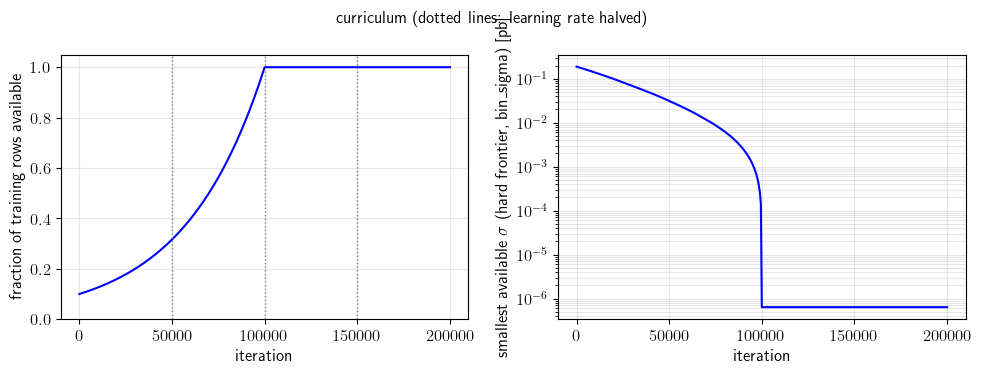

In [14]:
# ------------------------------------------------------------------
# The pacing: fraction of the training rows available, and the largest
# cross section among them, as functions of the iteration number
# ------------------------------------------------------------------
iterations = np.arange(0, config('n_iterations') + 1, max(1, config('n_iterations') // 400))
fraction   = np.array([train_loader.fraction(i) for i in iterations])

# With descending sort, the easiest (largest) rows are always first.
# As fraction grows, smaller (harder) sigma values enter.
# We plot the hard frontier: the smallest sigma currently in play.
sorted_score  = np.sort(score)          # ascending: index 0 = smallest (hardest)
N_score       = len(sorted_score)
avail         = np.maximum(1, (fraction * N_score).astype(int))
hard_frontier = sorted_score[N_score - avail]  # smallest sigma now in play

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

ax = axes[0]
ax.plot(iterations, fraction, color='blue')
for step in range(1, config('n_steps')):
    ax.axvline(step * config('n_iters_per_step'), color='grey', linestyle=':', linewidth=1)
ax.set_xlabel('iteration')
ax.set_ylabel('fraction of training rows available')
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(iterations, hard_frontier, color='blue')
ax.set_yscale('log')
ax.set_xlabel('iteration')
ax.set_ylabel(f'smallest available $\\sigma$ (hard frontier, {DIFFICULTY}) [pb]')
ax.grid(True, which='both', alpha=0.3)

fig.suptitle('curriculum (dotted lines: learning rate halved)', fontsize=12)
fig.tight_layout()
plt.show()

## Empirical risk (that is, average loss)

The empirical risk, which is the **objective function** to be minimized, is defined by

\begin{align}
R_M(\omega) & = \frac{1}{M} \sum_{m=1}^{M} L(t_m, f_m),
\end{align}

where 

\begin{align*}
    f_m & \equiv f\boldsymbol{x}_m; \omega)
\end{align*}
is the machine learning model whose parameters $\omega$ are to be fitted by minimizing $R_M$. 
The quantity $x = m_{hh}, k_{lambda}, c_{t}, c_{tt}, c_{ggh}, c_{gghh}$ are the inputs to the model and the target $t$ is the predicted cross section (per 15 GeV in $m_{hh}$).

(Aside: The empirical risk $R_M$ approximates the **risk functional**
\begin{align}
R[f] & = \int \cdots \int \, p(t, \boldsymbol{x}) \, L(t, f(\boldsymbol{x}; \omega)) \, dt \, d\boldsymbol{x} ,
\end{align}
where the quantity $p(t, \boldsymbol{x}) \, dt\, d\boldsymbol{x}$ is the probability distribution of the training data from which the sample $\{ (t_m, \boldsymbol{x}_m), m = 1,\cdots, M \}$ is presumed to have been drawn.) 

We fit the model $f$ by minimizing the **absolute loss** (i.e., L1 loss)

\begin{align}
    L(t, f) &= |t - f| ,
\end{align}
where $f$ is given by the dot product
\begin{align}
    f \equiv \sigma(m_{hh}, \theta) & = \boldsymbol{c}(\theta) \cdot \boldsymbol{a}(m_{hh}) .
\end{align}
The 23 functions $a_i(m_{hh})$ are approximated with a *single* neural network with $m_{hh}$ as input and the values of the functions $a_i(m_{hh})$ as outputs. The calculus of variations shows that the minimum of the L1 loss occurs when
\begin{align}
    f(\boldsymbol{x}, \omega^*) & = \text{median}_t [ p(t \mid \boldsymbol{x}) ],
\end{align}
where $\omega^*$ denotes the best-fit value of $\omega$, $p(t \mid \boldsymbol{x}) = p(t,  \boldsymbol{x}) / p(\boldsymbol{x})$, and $p(t \mid \boldsymbol{x})$ is the (typically, *unknown*) conditional probability density of target $t$ given the input $\boldsymbol{x}$.

## Define model for cross section
`heftnet` models the mapping $f : m_{hh}, k_{lambda}, c_{t}, c_{tt}, c_{ggh}, c_{gghh} \rightarrow \sigma$ using the known functional dependence of the cross section on the Wilson coefficients, $\theta = k_{lambda}, c_{t}, c_{tt}, c_{ggh}, c_{gghh}$, and the unknown observable-dependent functions $\boldsymbol{a}$. The mapping $g : m_{hh} \rightarrow \boldsymbol{a}$ is modeled with a function of the form
\begin{align}
    a_j(m_{hh}) & = P_j(m_{hh}) e^{Q_j(m_{hh})},
\end{align}
where $P$ and $Q$ are neural networks with one input and 23 outputs.

## Loss functions

`DataLoss` computes the average loss over a batch, for the loss chosen above. The targets have two columns: the POWHEG cross section and its estimated noise variance, which only the CHI2 loss uses.

`HEFTObjective` adds the positivity penalty, if requested, to the data loss. It replaces `drwho`'s `Objective` and works the same way with `drwho`'s other tools. In evaluation mode (`objective.eval()`, used when the average losses are monitored) the penalty is left out.

In [15]:
class DataLoss(nn.Module):
    '''
    Average loss over a batch.
      f: predictions, shape [B]
      y: targets, shape [B, 1]; column 0 is the POWHEG cross section (pb)

    The CHI2 loss was removed after testing showed it gave worse results
    than L1Loss and required noise_var as a second target column.
    '''
    def __init__(self, kind, scale):
        super().__init__()
        self.kind  = kind
        self.scale = scale

    def forward(self, f, y):
        t = y[:, 0]   # column 0: the POWHEG cross section (pb)
        if self.kind == 'L1':
            # Exactly torch.nn.L1Loss(): mean of |f - t|, no scaling.
            # f.view(-1) flattens the model output from shape [B, 1] to [B]
            # so it matches the 1-D target vector t.
            return torch.mean(torch.abs(f.view(-1) - t))
        if self.kind == 'MSE':
            d = f.view(-1) - t
            return torch.mean(d**2) / self.scale**2
        raise ValueError(f"Unknown loss {self.kind!r}. Use 'L1' or 'MSE'.")


class HEFTObjective(nn.Module):
    '''
    The data loss plus, if positivity=True and in training mode, the penalty
        lam * mean( (max(0, -f_j) / scale)^2 )
    over n_points random points (theta, x), drawn afresh at every call.
    '''
    def __init__(self, model, data_loss, positivity, lam, scale,
                 theta_mean, theta_std, x_max, n_points=2048):
        super().__init__()
        self.model      = model
        self.data_loss  = data_loss
        self.positivity = positivity
        self.lam        = lam
        self.scale      = scale
        self.x_max      = x_max
        self.n_points   = n_points
        # buffers move with the objective when .to(DEVICE) is called
        self.register_buffer('theta_mean', torch.as_tensor(theta_mean, dtype=torch.float32))
        self.register_buffer('theta_std',  torch.as_tensor(theta_std,  dtype=torch.float32))

    def save(self, paramsfile):
        self.model.save(paramsfile)

    def random_points(self):
        # theta ~ Gaussian(mean, std) of the training points; x ~ uniform(0, x_max)
        device = self.theta_mean.device
        theta = self.theta_mean + self.theta_std * torch.randn(self.n_points, 5, device=device)
        x     = self.x_max * torch.rand(self.n_points, 1, device=device)
        return torch.cat((x, theta), dim=1)          # columns: mhh, klambda, ..., cgghh

    def penalty(self):
        f = self.model(self.random_points())
        return torch.mean(torch.relu(-f)**2) / self.scale**2

    def forward(self, x, y):
        R = self.data_loss(self.model(x), y)
        if self.positivity and self.training:
            R = R + self.lam * self.penalty()
        return R

## Train!

In [16]:
def train(objective, optimizer, scheduler, monitor,
          train_loader, train_small_loader, val_loader):
    
    for x, y in train_loader:

        # set mode to training so that training-specific
        # operations such as dropout, etc., are enabled.
        objective.train()

        # clear all gradients
        optimizer.zero_grad()

        # compute empirical risk
        R = objective(x, y)

        # compute gradients
        R.backward()

        # take one step downhill in the empirical risk landscape
        optimizer.step()

        # check whether to update learning rate
        scheduler.step()

        # I'm alive printout
        if monitor.step():

            # compute average losses on both a random subset of 
            # training data and validation data
            t_loss = mlp.compute_avg_loss(objective, train_small_loader)
            v_loss = mlp.compute_avg_loss(objective, val_loader)

            # return current learning rate
            lr = scheduler.lr()

            # update loss file
            monitor(t_loss, v_loss, lr)

In [17]:
# Set random seeds before model creation so that weight initialisation
# and all stochastic operations (CurriculumLoader batches, etc.) are
# reproducible. Change SEED in the switches cell to get a different run.
torch.manual_seed(SEED)   # PyTorch random number generator
np.random.seed(SEED)      # NumPy random number generator

model     = NN.HEFTNet().to(DEVICE)

data_loss = DataLoss(LOSS, SCALE)

objective = HEFTObjective(model, data_loss,
                          positivity=POSITIVITY, lam=LAMBDA, scale=SCALE,
                          theta_mean=X[:train_size, 1:].mean(axis=0),
                          theta_std=X[:train_size, 1:].std(axis=0),
                          x_max=X[:train_size, 0].max() + 0.005).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=config('base_lr'))

# Instantiate learning rate step scheduler
scheduler = mlp.LRStepScheduler(
    optimizer,  
    n_steps=config('n_steps'), 
    n_iters_per_step=config('n_iters_per_step'), 
    base_lr=config('base_lr'), 
    gamma=config('gamma'))

# Instantiate object that saves average losses to
# a csv file for realtime monitoring as well as
# the model with the lowest average loss.
monitor = mon.Monitor(
    config('n_iterations'),
    config('file/losses'),
    monitorstep=config('monitor_step'),
    newlossfile=True,
    frac=config('frac'),
    model=model,
    paramsfile=config('file/params'))

print(model)
print(f'Number of parameters: {mlp.number_of_parameters(model)}')

number of milestones:          3

Step | Milestone | LR
-----------------------------
   0 |         0 | 2.0e-03   
-----------------------------
   1 |     50000 | 1.0e-03   
   2 |    100000 | 5.0e-04   
   3 |    150000 | 2.5e-04   

HEFTNet(
  (P): Sequential(
    (0): Linear(in_features=1, out_features=25, bias=True)
    (1): ReLU()
    (2): Linear(in_features=25, out_features=25, bias=True)
    (3): ReLU()
    (4): Linear(in_features=25, out_features=25, bias=True)
    (5): ReLU()
    (6): Linear(in_features=25, out_features=25, bias=True)
    (7): ReLU()
    (8): Linear(in_features=25, out_features=25, bias=True)
    (9): ReLU()
    (10): Linear(in_features=25, out_features=25, bias=True)
    (11): ReLU()
    (12): Linear(in_features=25, out_features=23, bias=True)
    (13): Tanh()
  )
  (Q): Linear(in_features=1, out_features=23, bias=True)
)
Number of parameters: 3944


In [18]:
TRAIN = True

if TRAIN:
    monitor.start()
    train(objective, optimizer, scheduler, monitor,
          train_loader, train_loader_val, val_loader)

monlosses runs/L1_curr_b_log/dihiggs_losses.csv

		learning rate:  2.000e-03
     49900| 24.95%|00:01:52|00:05:37| 445.2 it/s|3.722e-03|3.437e-03|     49900|
		learning rate:  1.000e-03
     99900| 49.95%|00:03:45|00:03:46| 442.7 it/s|3.446e-03|3.137e-03|     99900|
		learning rate:  5.000e-04
    149900| 74.95%|00:05:39|00:01:53| 441.2 it/s|3.335e-03|2.960e-03|    149900|
		learning rate:  2.500e-04
    199900| 99.95%|00:07:34|00:00:00| 440.1 it/s|3.238e-03|2.904e-03|    199900|

## Plot NN vs. POWHEG cross section

In [19]:
# Reload the model the way heft_test.ipynb does: rebuild it from its
# class and load the saved parameters. Model.load() also calls eval().
model = NN.HEFTNet().to(DEVICE)
model.load(config('file/params'))

x, t = next(iter(test_loader))

y = model(x).detach().cpu().numpy()
t = t.detach().cpu().numpy()[:, 0]    # column 0: POWHEG cross section

Saving to file: runs/L1_curr_b_log/dihiggs_plots.png


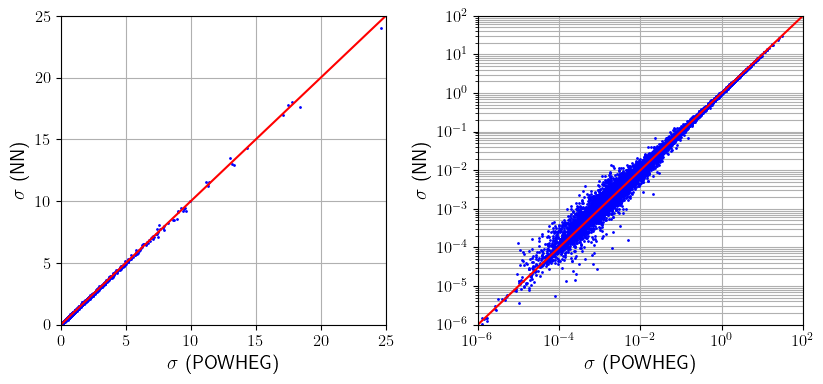

In [20]:
def plot_results(y, t, config,
                 xmin=1e-6, xmax=1e2, 
                 ymin=1e-6, ymax=1e2, 
                 ftsize=14):

    filename = config('file/plots')
    
    # create an empty figure
    fig = plt.figure(figsize=(8.4, 4))
 
    # add a subplot to it
    for i in range(2):
        nrows, ncols, index = 1,2,i+1
        ax  = fig.add_subplot(nrows, ncols, index)
                
        if i < 1:
            ax.set_xlim(0, 25)
            ax.set_ylim(0, 25)
        else:
            ax.set_xlim(xmin, xmax)
            ax.set_ylim(ymin, ymax)
            ax.set_xscale('log')
            ax.set_yscale('log')
                        
        ax.set_xlabel(r'$\sigma$ (POWHEG)', fontsize=ftsize)
        ax.set_ylabel(r'$\sigma$ (NN)', fontsize=ftsize)

        ax.plot(t, y, 'b', marker='.', markersize=2, linestyle='')
        ax.plot([xmin, xmax], [ymin, ymax], linestyle='solid', color='red')
    
        ax.grid(True, which="both", linestyle='-')

    fig.tight_layout()
    print(f'Saving to file: {filename}')
    plt.savefig(filename)
    plt.show()
    plt.close()
    
plot_results(y, t, config)

In [21]:
# ------------------------------------------------------------------
# How often does the trained model predict a negative cross section?
# ------------------------------------------------------------------
# 1. at 204,800 random points, drawn like those of the positivity penalty
model.eval()
with torch.no_grad():
    points = torch.cat([objective.random_points() for _ in range(100)])
    f_rand = model(points).cpu().numpy()

# 2. at the rows of the quick test set (y: predictions, t: POWHEG, from above)
print(f'negative predictions at random points: {np.mean(f_rand < 0):.3%}'
      f'   (most negative {f_rand.min():.2e} pb)')
print(f'negative predictions on the test set:  {np.mean(y < 0):.3%}'
      f'   (most negative {y.min():.2e} pb)')

negative predictions at random points: 0.111%   (most negative -2.62e-02 pb)
negative predictions on the test set:  0.112%   (most negative -1.23e-02 pb)


**IMPORTANT** Remember to terminate the realtime monitor window! 

In [22]:
if TRAIN:
    monitor.terminate()


	Terminating standalone loss monitor...
	Done!
